<a href="https://colab.research.google.com/github/alzatiro-create/analisis-regresi-jambi/blob/main/regresi_1_alza.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# REGRESI


In [ ]:
#Import Library
import numpy as np
import pandas as pd
import statsmodels.api as sm
# Membuat DataFrame dari data yang diberikan
data = {
'Partisipan': np.arange(1, 11),
'PMakan': [50, 40, 60, 55, 45, 65, 70, 75, 80, 90],
'PTranspor': [20, 25, 30, 35, 40, 50, 55, 60, 65, 70],
'BB': [60, 55, 65, 70, 62, 75, 80, 85, 90, 95]}
df = pd.DataFrame(data)
# Memisahkan variabel independen dan dependen
X = df[['PMakan', 'PTranspor']]
y = df['BB']
X = sm.add_constant(X) # Menambahkan kolom konstanta untuk intercept
model = sm.OLS(y, X) # Membangun model regresi
results = model.fit()
print(results.summary()) # Menampilkan hasil

                            OLS Regression Results                            
Dep. Variable:                     BB   R-squared:                       0.985
Model:                            OLS   Adj. R-squared:                  0.981
Method:                 Least Squares   F-statistic:                     234.6
Date:                Wed, 14 Oct 2026   Prob (F-statistic):           3.85e-07
Time:                        15:28:39   Log-Likelihood:                -18.626
No. Observations:                  10   AIC:                             43.25
Df Residuals:                       7   BIC:                             44.16
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         26.9870      2.879      9.374      0.0

In [ ]:
import pandas as pd

url = "https://raw.githubusercontent.com/Alam-A99/DATAAKSI/refs/heads/main/dataset_fiskal_97_hipoFull.csv"

# Membaca dataset
df = pd.read_csv(url, sep=None, engine='python')

# Memfilter semua baris yang mengandung teks "Jambi" (tidak peka huruf besar/kecil)
Jambi_data = df[df.apply(lambda row: row.astype(str).str.contains('Jambi', case=False).any(), axis=1)]

# Menampilkan hasil
print("Kota Jambi:")
display(Jambi_data)

Kota Jambi:


,Kota,Tahun,DBH_PAJAK,DBH_SDA,DBH_Lainnya,DAU_Grant,DAU_Earmark,DAK_Fisik,DAK_Nonfisik,PAD,...,bm_lingkungan,bm_ekonomi,bm_infrastruktur,bm_pariwisata,bm_perlindungan_sosial,KEMISKINAN,PENGANGGURAN,KETIMPANGAN,IPM,PE
253,Kota Jambi,2014,71.05,67.79,43.30,117.01,105.29,103.44,90.35,124.46,...,285.42,194.28,282.14,154.49,51.34,16.50,7.09,0.46,78.79,6.01
254,Kota Jambi,2015,94.62,39.91,52.08,163.33,108.59,72.92,74.48,235.65,...,91.84,272.66,210.27,112.80,237.06,16.25,9.36,0.45,74.93,7.37
255,Kota Jambi,2016,123.29,70.41,53.27,140.74,96.20,112.02,82.95,156.93,...,175.09,199.24,127.91,130.14,275.76,9.71,4.69,0.34,70.62,2.35
256,Kota Jambi,2017,107.58,49.11,38.44,192.47,98.71,130.05,118.47,256.46,...,222.72,252.54,181.33,83.74,84.93,9.08,7.85,0.35,83.48,2.84
257,Kota Jambi,2018,95.27,55.35,42.83,193.83,87.66,114.75,90.97,239.09,...,224.28,157.42,66.51,124.04,74.03,17.22,8.45,0.45,64.69,6.30
258,Kota Jambi,2019,111.68,57.08,47.08,133.51,82.80,67.95,123.52,163.46,...,212.16,237.46,293.14,193.07,156.14,13.36,3.27,0.43,68.08,4.62
259,Kota Jambi,2020,159.01,69.50,80.04,252.32,153.73,155.37,105.18,265.56,...,118.82,278.26,140.01,160.46,283.42,6.01,3.66,0.50,68.17,4.42
260,Kota Jambi,2021,153.31,115.24,84.76,190.20,88.28,119.75,95.89,173.52,...,89.05,193.03,169.47,136.68,185.60,10.41,8.49,0.41,67.82,2.82
261,Kota Jambi,2022,105.97,44.24,75.88,225.68,151.58,89.36,158.02,278.60,...,208.99,95.20,138.82,236.61,181.86,13.45,7.37,0.47,74.67,5.04
262,Kota Jambi,2023,173.51,109.54,62.85,235.97,121.08,107.11,139.18,336.12,...,199.83,117.20,220.63,273.38,85.28,18.94,5.39,0.41,65.29,2.76


In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.stats.api as sms
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy import stats
import plotly.graph_objects as go
import plotly.io as pio

# Memaksa Plotly untuk merender grafik interaktif di Google Colab
pio.renderers.default = 'colab'

# ---------------------------------------------------------
# 1. MEMBACA DATA LANGSUNG DARI URL GITHUB

url = "https://raw.githubusercontent.com/Alam-A99/DATAAKSI/refs/heads/main/dataset_fiskal_97_hipoFull.csv"

df_all = pd.read_csv(url, sep=None, engine='python')

# Membersihkan nama kolom
df_all.columns = df_all.columns.str.strip()

# Memfilter data khusus Kota Jambi
# Menggunakan pencarian pada seluruh baris agar sesuai
# dengan format dataset yang mungkin digunakan.

df = df_all[
    df_all.apply(
        lambda row: row.astype(str).str.contains(
            'Kota Jambi', case=False, regex=False
        ).any(),
        axis=1
    )
].copy()

print(f"Total data Kota Jambi yang dianalisis: {len(df)} baris.\n")

# Memastikan data ditemukan
if df.empty:
    raise ValueError(
        "Data Kota Jambi tidak ditemukan. "
        "Periksa nama wilayah dan format dataset."
    )

# Memastikan variabel tersedia
variabel = [
    'bm_ekonomi',
    'bm_perlindungan_sosial',
    'PENGANGGURAN'
]

for kolom in variabel:
    if kolom not in df.columns:
        raise ValueError(
            f"Kolom '{kolom}' tidak ditemukan. "
            f"Kolom yang tersedia: {df.columns.tolist()}"
        )

# Mengubah variabel menjadi numerik
for kolom in variabel:
    df[kolom] = pd.to_numeric(df[kolom], errors='coerce')

# Menghapus baris dengan data yang tidak lengkap
df = df.dropna(subset=variabel).copy()

print(f"Jumlah observasi setelah pembersihan: {len(df)} baris.\n")

if len(df) <= 3:
    raise ValueError(
        "Jumlah observasi terlalu sedikit untuk model "
        "dengan dua variabel bebas dan satu konstanta."
    )

# ---------------------------------------------------------
# 2. MODEL REGRESI DAN UJI ASUMSI KLASIK

# Variabel bebas (X)
X = df[['bm_ekonomi', 'bm_perlindungan_sosial']]

# Variabel terikat (Y)
Y = df['PENGANGGURAN']

# Menambahkan konstanta
X_sm = sm.add_constant(X)

# Menjalankan regresi linear berganda
model = sm.OLS(Y, X_sm).fit()

# Menampilkan ringkasan hasil regresi
print("=" * 60)
print("HASIL REGRESI LINEAR BERGANDA KOTA JAMBI")
print("=" * 60)

print(model.summary())

# ---------------------------------------------------------
# PERSAMAAN REGRESI

koef = model.params

def format_koef(nilai, nama):
    tanda = "+" if nilai >= 0 else "-"
    return f" {tanda} {abs(nilai):.4f}({nama})"

persamaan = (
    f"PENGANGGURAN = {koef['const']:.4f}"
    + format_koef(koef['bm_ekonomi'], 'BM_Ekonomi')
    + format_koef(
        koef['bm_perlindungan_sosial'],
        'BM_Perlindungan_Sosial'
    )
)

print("\n" + "=" * 60)
print("PERSAMAAN REGRESI KOTA JAMBI")
print("=" * 60)
print(persamaan)
print("=" * 60)

# ---------------------------------------------------------
# UJI ASUMSI KLASIK

print("\nHASIL UJI ASUMSI KLASIK")

# 1. Normalitas residual: Shapiro-Wilk
shapiro_stat, shapiro_p = stats.shapiro(model.resid)

print("\n1. Uji Normalitas (Shapiro-Wilk)")
print(f"   Statistik : {shapiro_stat:.4f}")
print(f"   P-value   : {shapiro_p:.4f}")

if shapiro_p > 0.05:
    print("   Kesimpulan: Tidak terdapat bukti kuat residual")
    print("   menyimpang dari distribusi normal.")
else:
    print("   Kesimpulan: Residual menunjukkan penyimpangan")
    print("   dari distribusi normal.")

# 2. Multikolinearitas: VIF
# VIF dihitung pada variabel bebas tanpa konstanta.
vif_data = pd.DataFrame()
vif_data["Variabel"] = X.columns
vif_data["VIF"] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

print("\n2. Uji Multikolinearitas (VIF)")
print(vif_data.to_string(index=False))

if vif_data["VIF"].max() < 10:
    print("   Kesimpulan: VIF kedua variabel kurang dari 10.")
else:
    print("   Kesimpulan: Terdapat indikasi multikolinearitas")
    print("   yang perlu diperiksa lebih lanjut.")

# 3. Heteroskedastisitas: Breusch-Pagan
bp_test = sms.het_breuschpagan(
    model.resid,
    model.model.exog
)

print("\n3. Uji Heteroskedastisitas (Breusch-Pagan)")
print(f"   P-value: {bp_test[1]:.4f}")

if bp_test[1] > 0.05:
    print("   Kesimpulan: Tidak terdapat bukti kuat")
    print("   heteroskedastisitas.")
else:
    print("   Kesimpulan: Terdapat indikasi heteroskedastisitas.")

# 4. Autokorelasi: Durbin-Watson
dw_value = sm.stats.stattools.durbin_watson(model.resid)

print("\n4. Uji Autokorelasi (Durbin-Watson)")
print(f"   Nilai Durbin-Watson: {dw_value:.4f}")
print("   Nilai mendekati 2 umumnya menunjukkan autokorelasi")
print("   orde pertama yang tidak kuat.")

# ---------------------------------------------------------
# 3. VISUALISASI REGRESI 3D INTERAKTIF

# Membuat grid berdasarkan rentang variabel bebas
x_range = np.linspace(
    df['bm_ekonomi'].min(),
    df['bm_ekonomi'].max(),
    30
)

y_range = np.linspace(
    df['bm_perlindungan_sosial'].min(),
    df['bm_perlindungan_sosial'].max(),
    30
)

x_grid, y_grid = np.meshgrid(x_range, y_range)

# Menghitung nilai prediksi pada bidang regresi
z_grid = (
    koef['const']
    + koef['bm_ekonomi'] * x_grid
    + koef['bm_perlindungan_sosial'] * y_grid
)

# Membuat grafik
fig = go.Figure()

# Bidang regresi
fig.add_trace(
    go.Surface(
        x=x_grid,
        y=y_grid,
        z=z_grid,
        name='Bidang Regresi',
        colorscale='Viridis',
        opacity=0.75,
        showscale=False
    )
)

# Titik data aktual
fig.add_trace(
    go.Scatter3d(
        x=df['bm_ekonomi'],
        y=df['bm_perlindungan_sosial'],
        z=df['PENGANGGURAN'],
        mode='markers',
        name='Data Aktual',
        marker=dict(
            size=6,
            color='red',
            line=dict(color='white', width=1)
        )
    )
)

# Pengaturan tampilan grafik
fig.update_layout(
    title=(
        "Plot Regresi 3D Kota Jambi: "
        "Pengangguran terhadap BM Ekonomi dan "
        f"BM Perlindungan Sosial | R² = {model.rsquared:.3f}"
    ),
    template='plotly_dark',
    scene=dict(
        xaxis_title='BM Ekonomi',
        yaxis_title='BM Perlindungan Sosial',
        zaxis_title='Pengangguran'
    ),
    margin=dict(l=0, r=0, b=0, t=60)
)

# Menampilkan grafik interaktif
fig.show()


Total data Kota Jambi yang dianalisis: 11 baris.

Jumlah observasi setelah pembersihan: 11 baris.

HASIL REGRESI LINEAR BERGANDA KOTA JAMBI
                            OLS Regression Results                            
Dep. Variable:           PENGANGGURAN   R-squared:                       0.056
Model:                            OLS   Adj. R-squared:                 -0.180
Method:                 Least Squares   F-statistic:                    0.2367
Date:                Wed, 14 Oct 2026   Prob (F-statistic):              0.795
Time:                        17:49:45   Log-Likelihood:                -22.747
No. Observations:                  11   AIC:                             51.49
Df Residuals:                       8   BIC:                             52.69
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|    

# REGRESI 2D

Jumlah data Kota Jambi: 11

HASIL REGRESI LINEAR KOTA JAMBI
                            OLS Regression Results                            
Dep. Variable:             KEMISKINAN   R-squared:                       0.391
Model:                            OLS   Adj. R-squared:                  0.239
Method:                 Least Squares   F-statistic:                     2.571
Date:                Wed, 14 Oct 2026   Prob (F-statistic):              0.137
Time:                        18:00:22   Log-Likelihood:                -27.664
No. Observations:                  11   AIC:                             61.33
Df Residuals:                       8   BIC:                             62.52
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------

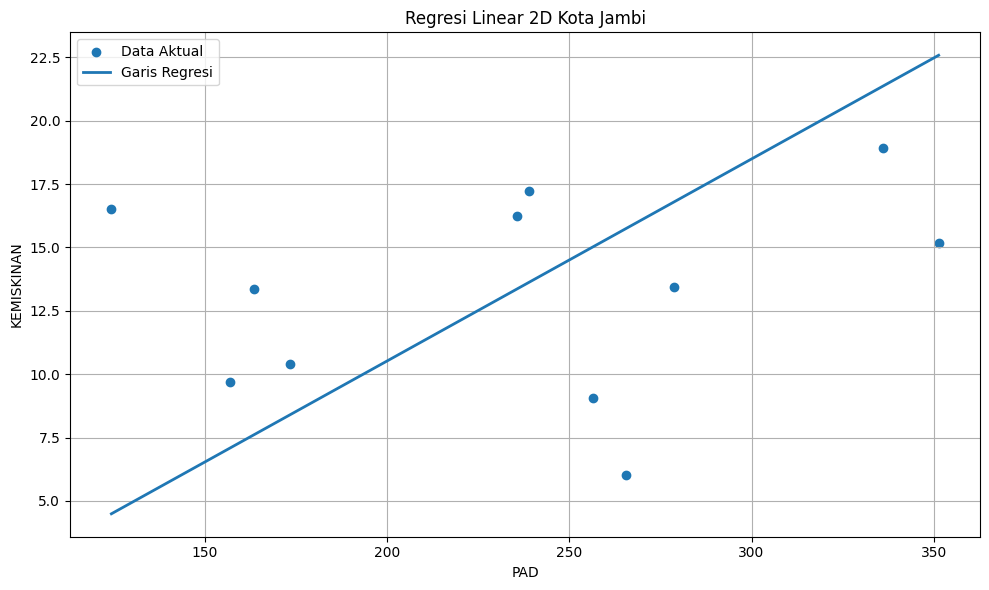

In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

# 1. Membaca data CSV dari GitHub
url = "https://raw.githubusercontent.com/Alam-A99/DATAAKSI/refs/heads/main/dataset_fiskal_97_hipoFull.csv"

df_all = pd.read_csv(url, sep=None, engine='python')
df_all.columns = df_all.columns.str.strip()

# 2. Memfilter data Kota Jambi
df = df_all[
    df_all.apply(
        lambda row: row.astype(str).str.contains(
            'Kota Jambi', case=False, regex=False
        ).any(),
        axis=1
    )
].copy()

print("Jumlah data Kota Jambi:", len(df))

if df.empty:
    raise ValueError("Data Kota Jambi tidak ditemukan.")

# 3. Menentukan variabel
variabel_x = ['PAD', 'DAU_Grant']
variabel_y = 'KEMISKINAN'

for kolom in variabel_x + [variabel_y]:
    if kolom not in df.columns:
        raise ValueError(f"Kolom {kolom} tidak ditemukan.")
    df[kolom] = pd.to_numeric(df[kolom], errors='coerce')

df = df.dropna(subset=variabel_x + [variabel_y]).copy()

if len(df) <= 3:
    raise ValueError("Jumlah observasi tidak cukup.")

# 4. Membuat model regresi
X = df[variabel_x]
Y = df[variabel_y]

X_sm = sm.add_constant(X)
model = sm.OLS(Y, X_sm).fit()

# 5. Menampilkan hasil regresi
print("\nHASIL REGRESI LINEAR KOTA JAMBI")
print(model.summary())

# 6. Menampilkan persamaan regresi
koef = model.params

persamaan = (
    f"KEMISKINAN = {koef['const']:.4f}"
    f" + ({koef['PAD']:.4f} * PAD)"
    f" + ({koef['DAU_Grant']:.4f} * DAU_Grant)"
)

print("\nPERSAMAAN REGRESI:")
print(persamaan)

print("\nR-squared:", round(model.rsquared, 4))
print("Adjusted R-squared:", round(model.rsquared_adj, 4))

# 7. Membuat garis regresi 2D
# DAU_Grant ditetapkan pada nilai rata-rata
pad_range = np.linspace(
    df['PAD'].min(),
    df['PAD'].max(),
    100
)

dau_mean = df['DAU_Grant'].mean()

data_prediksi = pd.DataFrame({
    'PAD': pad_range,
    'DAU_Grant': dau_mean
})

data_prediksi = sm.add_constant(
    data_prediksi,
    has_constant='add'
)

prediksi = model.predict(data_prediksi)

# 8. Membuat grafik
plt.figure(figsize=(10, 6))

plt.scatter(
    df['PAD'],
    df['KEMISKINAN'],
    label='Data Aktual'
)

plt.plot(
    pad_range,
    prediksi,
    linewidth=2,
    label='Garis Regresi'
)

plt.title('Regresi Linear 2D Kota Jambi')
plt.xlabel('PAD')
plt.ylabel('KEMISKINAN')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# REGRESI 3D

# REGRESI 3D

In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import plotly.graph_objects as go
import plotly.io as pio

# 1. Pengaturan Plotly untuk Google Colab
pio.renderers.default = 'colab'

# 2. Membaca data CSV dari GitHub
url = "https://raw.githubusercontent.com/Alam-A99/DATAAKSI/refs/heads/main/dataset_fiskal_97_hipoFull.csv"

df_all = pd.read_csv(url, sep=None, engine='python')
df_all.columns = df_all.columns.str.strip()

# 3. Memfilter data Kota Jambi
df = df_all[
    df_all.apply(
        lambda row: row.astype(str).str.contains(
            'Kota Jambi', case=False, regex=False
        ).any(),
        axis=1
    )
].copy()

print("Jumlah data Kota Jambi:", len(df))

if df.empty:
    raise ValueError("Data Kota Jambi tidak ditemukan.")

# 4. Menentukan variabel
variabel_x = ['PAD', 'DAU_Grant']
variabel_y = 'KEMISKINAN'

for kolom in variabel_x + [variabel_y]:
    if kolom not in df.columns:
        raise ValueError(f"Kolom {kolom} tidak ditemukan.")
    df[kolom] = pd.to_numeric(df[kolom], errors='coerce')

df = df.dropna(subset=variabel_x + [variabel_y]).copy()

if len(df) <= 3:
    raise ValueError("Jumlah observasi tidak cukup.")

# 5. Membuat model regresi
X = df[variabel_x]
Y = df[variabel_y]

X_sm = sm.add_constant(X)
model = sm.OLS(Y, X_sm).fit()

# 6. Menampilkan hasil regresi
print("\nHASIL REGRESI KOTA JAMBI")
print(model.summary())

# 7. Menampilkan persamaan regresi
koef = model.params

persamaan = (
    f"KEMISKINAN = {koef['const']:.4f}"
    f" + ({koef['PAD']:.4f} * PAD)"
    f" + ({koef['DAU_Grant']:.4f} * DAU_Grant)"
)

print("\nPERSAMAAN REGRESI:")
print(persamaan)

print("\nR-squared:", round(model.rsquared, 4))

# 8. Membuat grid untuk bidang regresi
pad_range = np.linspace(
    df['PAD'].min(),
    df['PAD'].max(),
    30
)

dau_range = np.linspace(
    df['DAU_Grant'].min(),
    df['DAU_Grant'].max(),
    30
)

pad_grid, dau_grid = np.meshgrid(
    pad_range,
    dau_range
)

# 9. Menghitung prediksi KEMISKINAN
kemiskinan_grid = (
    koef['const']
    + koef['PAD'] * pad_grid
    + koef['DAU_Grant'] * dau_grid
)

# 10. Membuat grafik 3D
fig = go.Figure()

# Bidang regresi
fig.add_trace(
    go.Surface(
        x=pad_grid,
        y=dau_grid,
        z=kemiskinan_grid,
        name='Bidang Regresi',
        colorscale='Viridis',
        opacity=0.8,
        showscale=False
    )
)

# Titik data aktual
fig.add_trace(
    go.Scatter3d(
        x=df['PAD'],
        y=df['DAU_Grant'],
        z=df['KEMISKINAN'],
        mode='markers',
        name='Data Aktual',
        marker=dict(
            size=6,
            color='red',
            line=dict(color='white', width=1)
        )
    )
)

# 11. Mengatur tampilan grafik
fig.update_layout(
    title=(
        "Regresi 3D Kemiskinan Kota Jambi"
        f" | R² = {model.rsquared:.3f}"),
    template='plotly_dark',
    scene=dict(
        xaxis_title='PAD',
        yaxis_title='DAU_Grant',
        zaxis_title='KEMISKINAN'),
    margin=dict(l=0, r=0, b=0, t=60) )

# 12. Menampilkan grafik
fig.show()

Jumlah data Kota Jambi: 11

HASIL REGRESI KOTA JAMBI
                            OLS Regression Results                            
Dep. Variable:             KEMISKINAN   R-squared:                       0.391
Model:                            OLS   Adj. R-squared:                  0.239
Method:                 Least Squares   F-statistic:                     2.571
Date:                Wed, 14 Oct 2026   Prob (F-statistic):              0.137
Time:                        18:02:21   Log-Likelihood:                -27.664
No. Observations:                  11   AIC:                             61.33
Df Residuals:                       8   BIC:                             62.52
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------